# Week 6 — Modeling with graphs: paths, flows, and networks

Companion notebook of the sixth lecture. A **graph** is a set of vertices joined by edges, and many questions that look unrelated become questions about one graph: a fastest route, a water-jug puzzle, a softball lineup, a pipe network. We build each graph with `networkx`, run the textbook algorithms **by hand once** (Dijkstra's labels, augmenting paths, the dynamic-programming recursion), then let the library do it. The case is the **2025 ICM Problem D** (Baltimore after the Key Bridge collapse): we rebuild Team 2519935's 39-node highway graph and reproduce their closeness-centrality figure.

**How to run**: Anaconda locally (`jupyter lab`), or Colab/Binder from the [course repository](https://github.com/liwt31/MathModel). Run cells in order with `Shift+Enter`.

**Note.** The exercises here and on the slides are **practice for yourself**, and they are **not** the graded assignments. Problem sets are released separately on Blackboard, with due dates.

In [1]:
import itertools as it
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
try:                                  # optional style file, ships with the course
    plt.style.use("mm.mplstyle")
except OSError:
    pass

## 1. A graph is two sets

A graph $G$ has a **vertex set** $V(G)$ and an **edge set** $E(G)$; each edge is a pair of vertices. The textbook's first example has 9 vertices and 12 edges. The **degree** $\deg(v)$ of a vertex counts the edges that touch it.

In [2]:
G = nx.Graph()
G.add_edges_from(["ac", "ad", "af", "bd", "bg", "ch", "di", "ef", "ei", "fg", "gh", "hi"])
print("|V| =", G.number_of_nodes(), "  |E| =", G.number_of_edges())
print("degrees:", dict(sorted(G.degree())))
print("c and h adjacent?", G.has_edge("c", "h"), "   b and c adjacent?", G.has_edge("b", "c"))
print("sum of degrees =", sum(d for _, d in G.degree()), "= 2|E|")

|V| = 9   |E| = 12
degrees: {'a': 3, 'b': 2, 'c': 2, 'd': 3, 'e': 2, 'f': 3, 'g': 3, 'h': 3, 'i': 3}
c and h adjacent? True    b and c adjacent? False
sum of degrees = 24 = 2|E|


Every edge has two ends, so the degrees always add up to $2|E|$ (the **handshake lemma**). A computer stores a graph either as this edge list or as an **adjacency matrix** $A$ with $A_{ij} = 1$ when $i$ and $j$ are adjacent (or the edge length, for weighted graphs).

In [3]:
A = nx.to_numpy_array(G, nodelist=sorted(G), dtype=int)
print("   " + " ".join(sorted(G)))
for v, row in zip(sorted(G), A):
    print(v, " ", " ".join(map(str, row)))

   a b c d e f g h i
a   0 0 1 1 0 1 0 0 0
b   0 0 0 1 0 0 1 0 0
c   1 0 0 0 0 0 0 1 0
d   1 1 0 0 0 0 0 0 1
e   0 0 0 0 0 1 0 0 1
f   1 0 0 0 1 0 1 0 0
g   0 1 0 0 0 1 0 1 0
h   0 0 1 0 0 0 1 0 1
i   0 0 0 1 1 0 0 1 0


## 2. Shortest paths: Dijkstra's labels, by hand once

The textbook's Figure 8.24 has six vertices and nine edges. Its figure leaves the diagonal $xy$ unlabeled; we give it length 5 (any nonnegative length leaves every answer below unchanged). Dijkstra's algorithm keeps a **temporary label** $L(i)$ on every vertex, makes the smallest one **permanent**, and updates its neighbors with $L(j) \leftarrow \min\{L(j),\, L(i) + c_{ij}\}$.

In [4]:
lengths = dict(uv=1, uw=7, ux=6, vw=2, wx=8, wy=3, xy=5, yz=4, xz=6)
H = nx.Graph()
for e, c in lengths.items():
    H.add_edge(e[0], e[1], weight=c)

def dijkstra_by_hand(graph, s, order="uvwxyz"):
    L = {v: np.inf for v in graph}; L[s] = 0
    pred = {s: None}
    permanent = set()
    while len(permanent) < len(graph):
        i = min((v for v in graph if v not in permanent), key=lambda v: L[v])   # smallest temporary label
        permanent.add(i)
        for j in graph[i]:
            if j not in permanent and L[i] + graph[i][j]["weight"] < L[j]:
                L[j] = L[i] + graph[i][j]["weight"]; pred[j] = i
        print("L =", tuple(f"{L[v]:g}" + ("*" if v in permanent else "") for v in order))
    return L, pred

L, pred = dijkstra_by_hand(H, "u")

L = ('0*', '1', '7', '6', 'inf', 'inf')
L = ('0*', '1*', '3', '6', 'inf', 'inf')
L = ('0*', '1*', '3*', '6', '6', 'inf')
L = ('0*', '1*', '3*', '6*', '6', '12')
L = ('0*', '1*', '3*', '6*', '6*', '10')
L = ('0*', '1*', '3*', '6*', '6*', '10*')


In [5]:
def path_to(pred, t):
    path = [t]
    while pred[path[-1]] is not None:
        path.append(pred[path[-1]])
    return path[::-1]
print("u -> z:", "-".join(path_to(pred, "z")), " length", L["z"])
print("networkx agrees:", nx.single_source_dijkstra(H, "u")[0])
print("hop distance d(u, y) =", nx.shortest_path_length(H, "u", "y"), " (ignoring lengths)")

u -> z: u-v-w-y-z  length 10
networkx agrees: {'u': 0, 'v': 1, 'w': 3, 'x': 6, 'y': 6, 'z': 10}
hop distance d(u, y) = 2  (ignoring lengths)


In iteration four $x$ and $y$ tie at 6; our code takes $x$ first (alphabetical), the textbook takes $y$, and the final labels are the same either way. Each label carries its **predecessor** (the vertex it was updated from), so the path comes out by walking the predecessors back from the target. The same code solves every source-to-all problem; that is why the algorithm stops with a label on *every* vertex, not just on $t$.

### Fewest roads or least time

A student drives from home $H$ to campus $C$. Through the town center $X$ the trip uses two road segments ($15 + 20 = 35$ minutes); along the expressway through $Y$ and $Z$ it uses three ($5 + 10 + 8 = 23$ minutes). The **distance** counts edges, the **shortest path** adds minutes, and they disagree.

In [6]:
M = nx.Graph()
M.add_weighted_edges_from([("H", "X", 15), ("X", "C", 20), ("H", "Y", 5), ("Y", "Z", 10), ("Z", "C", 8)])
print("fewest edges :", nx.shortest_path(M, "H", "C"), " d(H, C) =", nx.shortest_path_length(M, "H", "C"))
print("least time   :", nx.dijkstra_path(M, "H", "C"), " minutes =", nx.dijkstra_path_length(M, "H", "C"))

fewest edges : ['H', 'X', 'C']  d(H, C) = 2
least time   : ['H', 'Y', 'Z', 'C']  minutes = 23


### A puzzle as a shortest path: two jugs

With a 3-liter jug, a 5-liter jug, a tap and a sink, measure **exactly 4 liters**. A move fills a jug, empties it, or pours one jug into the other until the first is empty or the second is full. The vertices are the **states** $(a, b)$ (liters in the 3-liter and the 5-liter jug), an arc is one move, and every arc has length 1. The fewest moves is the shortest path from $(0, 0)$ to any state containing a 4.

In [7]:
def jug_graph(A, B):
    G = nx.DiGraph()
    for a in range(A + 1):
        for b in range(B + 1):
            p, q = min(a, B - b), min(b, A - a)          # how much each pour can move
            moves = {"fill small": (A, b), "fill big": (a, B), "empty small": (0, b), "empty big": (a, 0),
                     "pour small into big": (a - p, b + p), "pour big into small": (a + q, b - q)}
            for name, state in moves.items():
                if state != (a, b):                     # a move that changes nothing is not an arc
                    G.add_edge((a, b), state, move=name)
    return G

J = jug_graph(3, 5)
lab = nx.single_source_shortest_path_length(J, (0, 0))    # Dijkstra with all lengths 1 = breadth-first search
print(f"{J.number_of_nodes()} states, {len(lab)} reachable from (0, 0)")
for k in range(max(lab.values()) + 1):
    print(f"  L = {k}:", sorted(st for st, d in lab.items() if d == k))
print("never reached:", sorted(set(J) - set(lab)))

24 states, 16 reachable from (0, 0)
  L = 0: [(0, 0)]
  L = 1: [(0, 5), (3, 0)]
  L = 2: [(0, 3), (3, 2), (3, 5)]
  L = 3: [(0, 2), (3, 3)]
  L = 4: [(1, 5), (2, 0)]
  L = 5: [(1, 0), (2, 5)]
  L = 6: [(0, 1), (3, 4)]
  L = 7: [(0, 4), (3, 1)]
never reached: [(1, 1), (1, 2), (1, 3), (1, 4), (2, 1), (2, 2), (2, 3), (2, 4)]


In [8]:
goal = min((st for st in lab if 4 in st), key=lab.get)
plan = nx.shortest_path(J, (0, 0), goal)
for u, v in zip(plan, plan[1:]):
    print(f"{J[u][v]['move']:22s} -> {v}")
print("fewest moves:", lab[goal])

fill big               -> (0, 5)
pour big into small    -> (3, 2)
empty small            -> (0, 2)
pour big into small    -> (2, 0)
fill big               -> (2, 5)
pour big into small    -> (3, 4)
fewest moves: 6


The 8 states with both jugs partly full are never reached, because every move leaves a jug full or empty. Filling the big jug first reaches $(3, 4)$ in 6 moves; filling the small jug first reaches 4 liters only at $(0, 4)$ after 8 moves. The labels prove that 6 is the minimum.

### Dynamic programming on a staged network

The staged example of the slides: every path from vertex 1 to vertex 7 crosses the stages $\{1\} \to \{2, 3, 4\} \to \{5, 6\} \to \{7\}$. Backward recursion fills $f(v)$, the shortest distance from $v$ to vertex 7, starting from $f(7) = 0$; each value needs only the later ones.

In [9]:
stage_arcs = {(1, 2): 7, (1, 3): 8, (1, 4): 5, (2, 5): 12, (3, 5): 8, (3, 6): 9,
        (4, 5): 7, (4, 6): 13, (5, 7): 9, (6, 7): 6}
f = {7: 0}; nxt = {}
for v in [6, 5, 4, 3, 2, 1]:                           # later stages first
    options = {w: c + f[w] for (u, w), c in stage_arcs.items() if u == v}
    nxt[v] = min(options, key=options.get); f[v] = options[nxt[v]]
    print(f"f({v}) = min{options} = {f[v]}")
route = [1]
while route[-1] != 7:
    route.append(nxt[route[-1]])
print("shortest route:", " -> ".join(map(str, route)), " length", f[1])

f(6) = min{7: 6} = 6
f(5) = min{7: 9} = 9
f(4) = min{5: 16, 6: 19} = 16
f(3) = min{5: 17, 6: 15} = 15
f(2) = min{5: 21} = 21
f(1) = min{2: 28, 3: 23, 4: 21} = 21
shortest route: 1 -> 4 -> 5 -> 7  length 21


## 3. Maximum flow: augmenting paths, by hand once

Each arc $(i, j)$ of a directed graph has a **capacity** $u_{ij}$. Push flow from $s$ to $t$ along a directed path, as much as its weakest arc allows; subtract that amount on the path's arcs and **add it to the reverse arcs**, so a later path may undo it. Stop when the **residual graph** has no $s$–$t$ path. We search the path by breadth-first search (the Edmonds–Karp rule), so our path order may differ from the textbook's, but the total cannot.

In [10]:
from collections import deque

def max_flow_by_hand(arcs, s, t):
    r = {}                                          # residual capacities
    for (i, j), c in arcs.items():
        r[(i, j)] = r.get((i, j), 0) + c
        r.setdefault((j, i), 0)
    nbrs = {}
    for (i, j) in r:
        nbrs.setdefault(i, []).append(j)
    total = 0
    while True:
        prev = {s: None}; q = deque([s])            # breadth-first search in the residual graph
        while q and t not in prev:
            i = q.popleft()
            for j in nbrs[i]:
                if j not in prev and r[(i, j)] > 0:
                    prev[j] = i; q.append(j)
        if t not in prev:
            return total, r
        path = [t]
        while prev[path[-1]] is not None:
            path.append(prev[path[-1]])
        path = path[::-1]
        push = min(r[(a, b)] for a, b in zip(path, path[1:]))
        for a, b in zip(path, path[1:]):
            r[(a, b)] -= push; r[(b, a)] += push
        total += push
        print(f"path {'-'.join(map(str, path)):12s} pushes {push}   total {total}")

fig825 = {("s", "a"): 4, ("s", "b"): 5, ("a", "b"): 3, ("a", "c"): 2, ("b", "c"): 1,
          ("b", "d"): 6, ("d", "c"): 2, ("c", "t"): 7, ("d", "t"): 3}
value, residual = max_flow_by_hand(fig825, "s", "t")
print("maximum flow =", value)

path s-a-c-t      pushes 2   total 2
path s-b-c-t      pushes 1   total 3
path s-b-d-t      pushes 3   total 6
path s-b-d-c-t    pushes 1   total 7
path s-a-b-d-c-t  pushes 1   total 8
maximum flow = 8


**Why stopping is safe: the cut certificate.** When no path is left, the vertices reachable from $s$ in the residual graph form a set $S$; every arc from $S$ to the rest is saturated, so the flow equals the **capacity of that cut**. No flow can exceed any cut's capacity, so this flow is maximal (the max-flow min-cut theorem).

In [11]:
F = nx.DiGraph()
for (i, j), c in fig825.items():
    F.add_edge(i, j, capacity=c)
cut_value, (S_side, T_side) = nx.minimum_cut(F, "s", "t")
print("min cut value:", cut_value, "  S =", sorted(S_side), "  T =", sorted(T_side))
print("arcs crossing the cut:", [(i, j, c) for (i, j), c in fig825.items() if i in S_side and j in T_side])

fig_rev = {("s", 2): 10, ("s", 3): 10, (2, 3): 2, (2, 4): 4, (2, 5): 8, (3, 5): 9,
           (4, "t"): 10, (5, 4): 6, (5, "t"): 10}
print("\nthe reverse-arc example:")
print("maximum flow =", max_flow_by_hand(fig_rev, "s", "t")[0])

min cut value: 8   S = ['a', 'b', 'd', 's']   T = ['c', 't']
arcs crossing the cut: [('a', 'c', 2), ('b', 'c', 1), ('d', 'c', 2), ('d', 't', 3)]

the reverse-arc example:
path s-2-4-t      pushes 4   total 4
path s-2-5-t      pushes 6   total 10
path s-3-5-t      pushes 4   total 14
path s-3-5-4-t    pushes 5   total 19
maximum flow = 19


### Maximum flow is a linear program

Week 5's solver solves the same problem: variables $x_{ij}$ (flow on each arc), objective $\max \sum_j x_{sj}$, flow balance at every inner vertex, and $0 \le x_{ij} \le u_{ij}$ (textbook formulation 8.22).

In [12]:
from scipy.optimize import linprog
arcs = list(fig825)
inner = ["a", "b", "c", "d"]
c_obj = [-1 if i == "s" else 0 for (i, j) in arcs]            # maximize flow out of s
A_eq = [[(1 if j == v else 0) - (1 if i == v else 0) for (i, j) in arcs] for v in inner]
res = linprog(c_obj, A_eq=A_eq, b_eq=[0] * len(inner),
              bounds=[(0, fig825[a]) for a in arcs], method="highs")
print("LP maximum flow =", -res.fun)
print({f"{i}{j}": round(x, 3) for (i, j), x in zip(arcs, res.x)})

LP maximum flow = 8.0
{'sa': np.float64(3.0), 'sb': np.float64(5.0), 'ab': np.float64(1.0), 'ac': np.float64(2.0), 'bc': np.float64(1.0), 'bd': np.float64(5.0), 'dc': np.float64(2.0), 'ct': np.float64(5.0), 'dt': np.float64(3.0)}


## 4. Matching and the softball manager

A **matching** is a set of edges with no shared vertex. In a bipartite graph (players on one side, positions on the other), a maximum matching is a maximum flow: arcs $s \to$ player and position $\to t$ of capacity 1, arcs player $\to$ position for every allowed pair. First the textbook's small example, where a greedy start gets stuck at 2.

In [13]:
B = nx.Graph()
X_side = ["x1", "x2", "x3", "x4"]
B.add_edges_from([("x1", "y1"), ("x1", "y2"), ("x1", "y4"), ("x1", "y5"), ("x2", "y3"), ("x2", "y6"),
                  ("x3", "y1"), ("x3", "y3"), ("x4", "y1"), ("x4", "y3")])
greedy = [("x1", "y1"), ("x2", "y3")]               # the text's greedy start
used = {v for e in greedy for v in e}
print("greedy start:", greedy, "  edges still addable:", [e for e in B.edges() if not used & set(e)])
M = nx.bipartite.maximum_matching(B, top_nodes=X_side)
print("maximum matching:", sorted((x, M[x]) for x in X_side if x in M), " size", sum(x in M for x in X_side))

greedy start: [('x1', 'y1'), ('x2', 'y3')]   edges still addable: []
maximum matching: [('x1', 'y2'), ('x2', 'y6'), ('x3', 'y3'), ('x4', 'y1')]  size 4


In [14]:
table81 = {"Al": [2, 8], "Bo": [1, 5, 7], "Che": [2, 3], "Doug": [1, 4, 5, 6, 7], "Ella": [3, 8],
           "Fay": [10, 11], "Gene": [3, 8, 11], "Hal": [2, 4, 9], "Ian": [8, 9, 10], "John": [1, 5, 6, 7],
           "Kit": [8, 9], "Leo": [3, 9, 11], "Moe": [1, 4, 6, 7], "Ned": [], "Paul": [9, 10]}

def lineup(table):
    N = nx.DiGraph()
    for p, positions in table.items():
        N.add_edge("s", p, capacity=1)
        for k in positions:
            N.add_edge(p, f"pos{k}", capacity=1)
    for k in range(1, 12):
        N.add_edge(f"pos{k}", "t", capacity=1)
    value, flow = nx.maximum_flow(N, "s", "t")
    return value, {p: q for p in table for q, x in flow.get(p, {}).items() if x > 0.5}

v1, a1 = lineup(table81)
print("Table 8.1: max flow =", v1, a1)
table82 = dict(table81, Hal=[2, 9])                 # Hal can no longer play second base
v2, a2 = lineup(table82)
print("Table 8.2: max flow =", v2, "-> no feasible lineup" if v2 < 11 else "")

Table 8.1: max flow = 11 {'Bo': 'pos7', 'Che': 'pos2', 'Doug': 'pos6', 'Ella': 'pos3', 'Hal': 'pos4', 'Ian': 'pos9', 'John': 'pos5', 'Kit': 'pos8', 'Leo': 'pos11', 'Moe': 'pos1', 'Paul': 'pos10'}
Table 8.2: max flow = 10 -> no feasible lineup


With Table 8.2 the five positions 1, 4, 5, 6, 7 (pitcher, second base, third base, shortstop, left field) can be played only by Bo, Doug, John and Moe: four players for five positions. The maximum flow drops to 10, and the minimum cut proves that **no** lineup exists.

### The 0–1 matrix problem

Is there a $4 \times 6$ matrix of 0s and 1s with row sums $(3, 2, 3, 4)$ and column sums $(3, 2, 2, 3, 1, 1)$? Arcs $s \to r_i$ with capacity $r_i$, $c_j \to t$ with capacity $s_j$, and $r_i \to c_j$ with capacity 1; a flow of $3 + 2 + 3 + 4 = 12$ answers yes, and the unit arcs that carry flow are the 1s.

In [15]:
rows, cols = [3, 2, 3, 4], [3, 2, 2, 3, 1, 1]
N = nx.DiGraph()
for i, ri in enumerate(rows):
    N.add_edge("s", f"r{i}", capacity=ri)
    for j in range(len(cols)):
        N.add_edge(f"r{i}", f"c{j}", capacity=1)
for j, sj in enumerate(cols):
    N.add_edge(f"c{j}", "t", capacity=sj)
value, flow = nx.maximum_flow(N, "s", "t")
M01 = np.array([[round(flow[f"r{i}"][f"c{j}"]) for j in range(len(cols))] for i in range(len(rows))])
print("max flow =", value, "of", sum(rows)); print(M01)
print("row sums", M01.sum(1), " column sums", M01.sum(0))

max flow = 12 of 12
[[0 0 0 1 1 1]
 [1 0 0 1 0 0]
 [1 1 1 0 0 0]
 [1 1 1 1 0 0]]
row sums [3 2 3 4]  column sums [3 2 2 3 1 1]


## 5. Centrality: which vertices matter

Network studies rank vertices by **centrality**. Three standard measures, on a graph with $N$ vertices and hop distance $d(v, t)$:

* **degree**: the number of neighbors;
* **closeness** $CC(v) = (N - 1) / \sum_{t} d(v, t)$, the inverse of the average distance from $v$ to everyone;
* **betweenness**: the share of shortest paths between other pairs that pass through $v$.

On the Dijkstra graph (lengths ignored):

In [16]:
for name, f in [("degree", lambda g: dict(g.degree())), ("closeness", nx.closeness_centrality),
                ("betweenness", lambda g: nx.betweenness_centrality(g, normalized=False))]:
    print(f"{name:12s}", {v: round(x, 3) for v, x in sorted(f(H).items())})

degree       {'u': 3, 'v': 2, 'w': 4, 'x': 4, 'y': 3, 'z': 2}
closeness    {'u': 0.714, 'v': 0.556, 'w': 0.833, 'x': 0.833, 'y': 0.714, 'z': 0.556}
betweenness  {'u': 0.833, 'v': 0.0, 'w': 2.667, 'x': 2.667, 'y': 0.833, 'z': 0.0}


## 6. Case: 2025 ICM Problem D, Baltimore after the Key Bridge

On 26 March 2024 a container ship struck the **Francis Scott Key Bridge**, which carried the Baltimore Beltway (I-695) across the outer harbor, and the bridge collapsed. Team **2519935** (Outstanding) abstracts the region's highways into a graph of **39 vertices**, the interchanges of their Figure 7(a). Graph $G_2$ has the bridge edge between their map nodes 37 and 39 (before the collapse); graph $G$ lacks it (after). They compare the **closeness centrality** of every node in $G$ and $G_2$ (their Figure 8).

The paper does not list the edges. We digitized all 60 edges of $G$ from their Figure 7(b), whose labels run 0–38 (map node $k$ is graph node $k - 1$; the bridge is the edge 36–38).

In [17]:
edges_G = [(0, 1), (0, 4), (1, 2), (1, 5), (2, 3), (3, 6), (4, 5), (4, 9), (5, 6), (5, 13), (6, 7), (6, 15),
           (7, 31), (7, 34), (8, 9), (8, 11), (9, 12), (10, 11), (10, 16), (11, 12), (12, 22), (12, 26),
           (13, 14), (13, 26), (14, 15), (14, 27), (15, 28), (16, 17), (17, 18), (18, 19), (19, 20), (19, 21),
           (20, 23), (20, 37), (21, 22), (21, 23), (22, 23), (22, 24), (23, 24), (24, 25), (24, 30), (25, 26),
           (25, 29), (26, 27), (27, 28), (27, 29), (28, 29), (28, 31), (29, 30), (30, 31), (30, 32), (30, 33),
           (31, 32), (31, 34), (32, 33), (32, 34), (33, 35), (33, 36), (34, 35), (37, 38)]
G_after = nx.Graph(edges_G)
G_before = G_after.copy(); G_before.add_edge(36, 38)          # the Key Bridge
print("G :", G_after.number_of_nodes(), "nodes,", G_after.number_of_edges(), "edges")
print("G2:", G_before.number_of_nodes(), "nodes,", G_before.number_of_edges(), "edges")

cc_after = nx.closeness_centrality(G_after)       # hop distances: the edges carry no lengths
cc_before = nx.closeness_centrality(G_before)
for v in [0, 12, 24, 35, 36, 37, 38]:
    print(f"node {v:2d}:  G {cc_after[v]:.3f}   G2 {cc_before[v]:.3f}")

G : 39 nodes, 60 edges
G2: 39 nodes, 61 edges
node  0:  G 0.213   G2 0.213
node 12:  G 0.317   G2 0.317
node 24:  G 0.317   G2 0.317
node 35:  G 0.222   G2 0.230
node 36:  G 0.197   G2 0.218
node 37:  G 0.196   G2 0.207
node 38:  G 0.165   G2 0.203


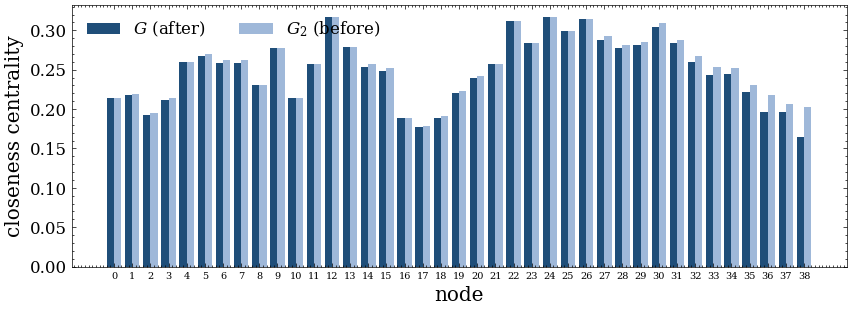

In [18]:
nodes = range(39)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(np.array(nodes) - 0.2, [cc_after[v] for v in nodes], 0.4, color="#1F4E79", label="$G$ (after)")
ax.bar(np.array(nodes) + 0.2, [cc_before[v] for v in nodes], 0.4, color="#9FB8D9", label="$G_2$ (before)")
ax.set_xticks(list(nodes)); ax.tick_params(axis="x", labelsize=7)
ax.set_xlabel("node"); ax.set_ylabel("closeness centrality"); ax.legend(frameon=False, ncol=2)
plt.show()

Compare with the paper's Figure 8: every bar agrees to the three digits we can read (node 12: 0.317 in both graphs; node 38: 0.165 after, 0.203 before). So the paper's closeness uses **hop distance**: every highway segment counts as one step, whatever its length. Their reading of the figure stands as well: nodes 0–26 barely move, and nodes 35–38 near the bridge lose the most.

### What the bridge edge carries

Closeness summarizes the change in one number per node. The underlying distances say more, and a max-flow computation (unit capacities: how many routes share no edge, by Menger's theorem) says how fragile the crossing becomes.

In [19]:
d_before = dict(nx.all_pairs_shortest_path_length(G_before))
d_after = dict(nx.all_pairs_shortest_path_length(G_after))
changed = [(u, v) for u, v in it.combinations(range(39), 2) if d_before[u][v] != d_after[u][v]]
print("hops 36 -> 38: before", d_before[36][38], " after", d_after[36][38], " detour", nx.shortest_path(G_after, 36, 38))
print("pairs whose distance changes:", len(changed), "of", 39 * 38 // 2)
print("node 38 total distance:", sum(d_before[38].values()), "->", sum(d_after[38].values()),
      "  closeness 38/231 =", round(38 / 231, 3))
for name, g in [("before", G_before), ("after", G_after)]:
    D = g.to_directed()
    nx.set_edge_attributes(D, 1, "capacity")
    print(f"edge-disjoint routes 36 -> 38 {name}: max flow =", nx.maximum_flow_value(D, 36, 38))

hops 36 -> 38: before 1  after 7  detour [36, 33, 30, 24, 23, 20, 37, 38]
pairs whose distance changes: 28 of 741
node 38 total distance: 187 -> 231   closeness 38/231 = 0.165
edge-disjoint routes 36 -> 38 before: max flow = 2
edge-disjoint routes 36 -> 38 after: max flow = 1


### The traffic counts: commuters and non-commuters

For local roads the team uses the Maryland traffic counts (`MDOT_SHA_Annual_Average_Daily_Traffic_Baltimore.csv`, provided with the problem): **AADT** is the annual average daily traffic (all 7 days), **AAWDT** the annual average weekday traffic. They assume $J$ commuters drive on weekdays only and $K$ non-commuters every day, so (their Eq. 7)

$$\mathrm{AADT} = \frac{5J + 7K}{7}, \qquad \mathrm{AAWDT} = J + K.$$

Solving the two linear equations gives $K = \tfrac12(7\,\mathrm{AADT} - 5\,\mathrm{AAWDT})$ and $J = \tfrac72(\mathrm{AAWDT} - \mathrm{AADT})$. The baseline is the 2014–2022 mean (their Eq. 6), and the impact coefficient is $\beta = (\text{current})/(\text{baseline})$.

In [20]:
import pandas as pd
FILE = "MDOT_SHA_Annual_Average_Daily_Traffic_Baltimore.csv"
URL = "https://raw.githubusercontent.com/liwt31/MathModel/refs/heads/2026/data/" + FILE
try:
    df = pd.read_csv(URL)
except Exception:                       # offline fallback: the repo's data/ folder
    df = pd.read_csv("data/" + FILE)
print(df.shape)

years = range(2014, 2023)
aadt0 = df[[f"AADT {y}" for y in years]].mean(axis=1)
aawdt0 = df[[f"AAWDT {y}" for y in years]].mean(axis=1)
aadt1, aawdt1 = df["AADT (Current)"], df["AAWDT (Current)"]
J = lambda a, w: 3.5 * (w - a)           # weekday-only traffic (solving Eq. 7)
K = lambda a, w: 0.5 * (7 * a - 5 * w)   # every-day traffic
df["beta_J"] = J(aadt1, aawdt1) / J(aadt0, aawdt0)
df["beta_K"] = K(aadt1, aawdt1) / K(aadt0, aawdt0)

tunnel = df["Road Name"].str.contains("HARBOR TUNNEL", na=False)
print("Harbor Tunnel stations:", tunnel.sum())
print(f"mean beta, weekday-only traffic J : {df.loc[tunnel, 'beta_J'].mean():.3f}")
print(f"mean beta, every-day traffic K    : {df.loc[tunnel, 'beta_K'].mean():.3f}")

(2398, 62)
Harbor Tunnel stations: 14
mean beta, weekday-only traffic J : 0.751
mean beta, every-day traffic K    : 1.145


The paper reports, for the Baltimore Harbor Tunnel Thruway, commuter traffic **+14%** and non-commuter traffic **−25%**. Our means are $0.751$ ($-24.9\%$) for the commuters $J$ and $1.145$ ($+14.5\%$) for the non-commuters $K$. The numbers match the paper's, and the groups are reversed, because the paper's Eq. (8) swaps the two formulas: it computes its "commuters" with $\tfrac12(7\,\mathrm{AADT} - 5\,\mathrm{AAWDT})$, which is the formula for $K$, and its "non-commuters" with $\tfrac72(\mathrm{AAWDT} - \mathrm{AADT})$, the formula for $J$. On the tunnel, every-day traffic grew and weekday-only traffic fell. Check by substitution: $J = 1$, $K = 0$ gives $\mathrm{AADT} = 5/7$, $\mathrm{AAWDT} = 1$, and $\tfrac72(1 - 5/7) = 1$.

One more data check: which year is "Current"? The station on the bridge itself still reports traffic.

In [21]:
key = df["Station Description"].astype(str).str.contains("Francis Scott Key Bridge")
print(df.loc[key, ["Station Description", "AADT 2022", "AADT (Current)"]].drop_duplicates().to_string(index=False))
ramp = df["Road Name"].astype(str).str.contains(r"RAMP 5 FR RAMP 9 \(FR MD695\)")
print("\nRAMP 5 FR RAMP 9 (FR MD695) TO MD 157 SB:",
      "beta_J =", round(df.loc[ramp, "beta_J"].iloc[0], 2), " beta_K =", round(df.loc[ramp, "beta_K"].iloc[0], 2),
      "  (paper: 11.994)")

               Station Description  AADT 2022  AADT (Current)
MD 695 at Francis Scott Key Bridge    33195.0           34121

RAMP 5 FR RAMP 9 (FR MD695) TO MD 157 SB: beta_J = 7.2  beta_K = 13.53   (paper: 11.994)


The Key Bridge station reports $34{,}121$ vehicles per day in the Current column, slightly above its 2022 count, so at least this count predates the collapse; the comparison measures change between the 2014–2022 mean and the current count year. The paper's largest coefficient, $11.994$ on a Beltway ramp, comes out as $13.5$ and $7.2$ in our rebuild; the paper does not say how it combined the two groups or which baseline rows it kept, so we report ours as computed.

## Practice exercises

**These are practice for yourself, and they are not the graded assignments.** Problem sets are released separately on Blackboard, with due dates.

1. **Two other jugs.** With a 4-liter and a 9-liter jug, measure exactly 6 liters. Call `jug_graph(4, 9)`, find the fewest moves, and say which jug to fill first.
2. **Negative lengths.** Build a three-vertex graph with one negative edge where `dijkstra_by_hand` returns a wrong label. Why can a permanent label be wrong once lengths may be negative?
3. **A 0–1 matrix.** Does a $3 \times 4$ 0–1 matrix with row sums $(3, 2, 2)$ and column sums $(2, 2, 2, 1)$ exist? Adapt the 0–1 matrix cell and decide.
4. **Basketball lineup.** Positions 1–5; Alice 1,2; Bonnie 1; Courtney 1,2; Deb 3,4,5; Ellen 2; Fay 1; Gladys 3,4; Hermione 2,3. Find a lineup by maximum flow; what changes if Hermione cannot play 3?
5. **A second bridge.** In the 39-node case graph, add one more edge of your choice near the harbor. Which single edge raises the closeness of node 38 the most, and by how much?
6. **Travel times.** Give each case edge a length (draw them from 2–10 minutes at random) and recompute closeness with `distance="weight"`. Does the ranking of the most affected nodes survive?
